# Conformal prediction intervals for a weather forecaster

Add intervals with a 90% coverage guarantee to any trained forecaster, after training.

Most forecasting models output a single number. **Split conformal prediction** adds an interval
around it after training, with a simple recipe and a guarantee:

1. Measure the forecast errors on data the model was not trained on (the *calibration* set).
2. Find the error size that 90% of these errors stay below.
3. Use it as the margin around every new forecast.

If future data behaves like the calibration data, the intervals contain the truth at least 90%
of the time, whatever the model: no retraining, no assumption about the error distribution.

In [ ]:
# Install keras-proba, then choose a backend: "jax", "tensorflow" or "torch".
!pip install -q keras-proba
import os

os.environ["KERAS_BACKEND"] = "jax"

## Load the data

Predict the temperature 24 hours ahead from the last 48 hours of the
[Jena climate](https://www.bgc-jena.mpg.de/wetter/) data. We train on 2009-2014, calibrate on
the following year, and test on the last year.

In [2]:
import glob

import matplotlib.pyplot as plt
import numpy as np

import keras
import keras_proba

keras.utils.set_random_seed(0)
LOOKBACK, HORIZON = 48, 24  # Hours.

path = keras.utils.get_file(
    origin="https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",
    extract=True,
)
csv = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
data = np.genfromtxt(csv, delimiter=",", skip_header=1, usecols=(1, 2, 4, 5, 12), dtype="float32")[5::6]
data[:, 4] = np.maximum(data[:, 4], 0)  # -9999 marks missing wind measurements.
temperature = data[:, 1].copy()

train_end, cal_end = int(0.7 * len(data)), int(0.85 * len(data))
features = (data - data[:train_end].mean(0)) / data[:train_end].std(0)


def windows(start, stop):
    ends = np.arange(max(start, LOOKBACK), stop - HORIZON + 1)
    x = np.stack([features[t - LOOKBACK : t].reshape(-1) for t in ends])
    return x, temperature[ends + HORIZON - 1][:, None]


x_train, y_train = windows(0, train_end)
x_cal, y_cal = windows(train_end, cal_end)
x_test, y_test = windows(cal_end, len(data))

## A standard point forecaster

Any trained model works. This one is a plain regression network trained with the mean squared
error: it forecasts a temperature, with no idea of how far off it might be.

In [3]:
model = keras.Sequential(
    [
        keras.Input((x_train.shape[1],)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(1),
    ]
)
model.compile(optimizer="adam", loss="mse")
model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=256,
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=0,
)
forecast_cal, forecast_test = model.predict(x_cal, verbose=0), model.predict(x_test, verbose=0)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


## Calibrate the intervals

`SplitConformalRegressor` measures the absolute errors on the calibration year and keeps the
threshold that 90% of them stay below. The histogram shows those errors and the threshold.

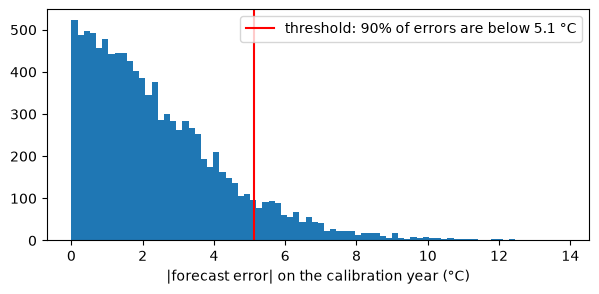

In [4]:
conformal = keras_proba.postprocessing.SplitConformalRegressor(alpha=0.1)  # alpha = 1 - 90%.
conformal.fit(y_cal, forecast_cal)
threshold = float(keras.ops.convert_to_numpy(conformal.quantile_)[0])

plt.figure(figsize=(7, 3))
plt.hist(np.abs(y_cal - forecast_cal)[:, 0], bins=80)
plt.axvline(threshold, color="r", label=f"threshold: 90% of errors are below {threshold:.1f} °C")
plt.xlabel("|forecast error| on the calibration year (°C)")
plt.legend()
plt.show()

## Forecast with intervals, and check them on the test year

Every forecast becomes `forecast ± threshold`. On the test year, unseen during training and
calibration, the intervals should contain the actual temperature about 90% of the time.

The 90% intervals contain the actual temperature 91.1% of the time on the test year


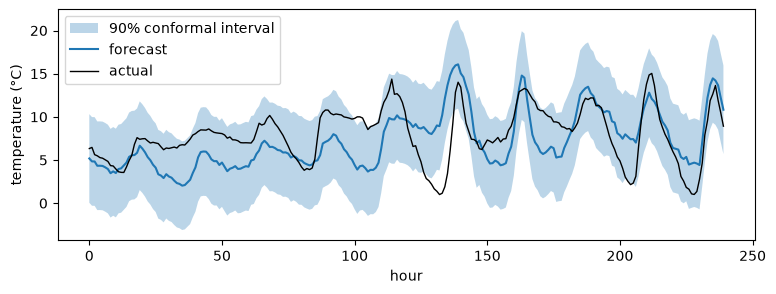

In [5]:
lower, upper = conformal.predict_interval(forecast_test)
coverage = float(keras.ops.convert_to_numpy(keras_proba.postprocessing.interval_coverage(y_test, lower, upper))[0])
print(f"The 90% intervals contain the actual temperature {coverage:.1%} of the time on the test year")

lower, upper = keras.ops.convert_to_numpy(lower)[:, 0], keras.ops.convert_to_numpy(upper)[:, 0]
hours = np.arange(24 * 10)
plt.figure(figsize=(9, 3))
plt.fill_between(hours, lower[hours], upper[hours], alpha=0.3, label="90% conformal interval")
plt.plot(hours, forecast_test[hours, 0], label="forecast")
plt.plot(hours, y_test[hours, 0], "k", lw=1, label="actual")
plt.xlabel("hour")
plt.ylabel("temperature (°C)")
plt.legend()
plt.show()

## What we learned

- Conformal prediction turns a model's errors on held-out data into intervals with a coverage
  guarantee, after training and for any model.
- The guarantee assumes the calibration data resembles future data. Weather changes from year
  to year, so calibrate on recent data and recalibrate regularly.
- These intervals all have the same width. Passing a per-forecast uncertainty (`scale=`, e.g.
  from a `GaussianHead`) makes them adapt to each input: see
  [conformal regression](https://anas-rz.github.io/keras-proba/examples/conformal_regression/).